# EDA internacional TSI

Este notebook ejecuta el analisis exploratorio sobre los resumenes del consolidado internacional. El consolidado completo se procesa por lotes fuera del notebook para no cargarlo entero en memoria.

La validacion de MySQL se incorporara cuando termine la carga completa.

In [2]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
OUTPUT = ROOT / "data" / "03_analysis_output"
EDA = OUTPUT / "eda"
QUALITY = OUTPUT / "calidad_cobertura"
TEMPORAL = OUTPUT / "analisis_temporal"
COMPARISON = OUTPUT / "comparacion_fuentes"
TSI = OUTPUT / "indicador_tsi"

perfil_global = json.loads((EDA / "perfil_global.json").read_text(encoding="utf-8"))
resumen_fuente = pd.read_json(EDA / "resumen_por_fuente.json")
nulos = pd.read_csv(EDA / "nulos_por_campo.csv")
perfil_global

{'filas': 41770880,
 'grupos_ciudad_fuente_metrica': 5,
 'timestamp_minimo': '2001-01-02T07:30:00',
 'timestamp_maximo': '2024-10-18T00:00:00',
 'batch_size': 250000,
 'max_rows': None,
 'input': 'C:\\Users\\REYES\\OneDrive\\Desktop\\terminado\\portafolio data science\\TSI\\data\\02_clean\\consolidated\\international_observations.parquet'}

In [3]:
columnas_resumen = ["ciudad", "fuente", "metrica_principal", "observaciones"]
resumen_fuente[columnas_resumen].sort_values("observaciones", ascending=False)

,ciudad,fuente,metrica_principal,observaciones
3,San Francisco Bay Area,pems_bay,velocidad_sensor,16937700
2,Madrid,madrid_traffic_points,intensidad,12512133
1,Los Angeles County,metr_la,velocidad_sensor,7094304
4,Sao Paulo,sao_paulo_cet,congestion_longitud_m,5223411
0,Istanbul,istanbul_traffic_index,indice_congestion,3332


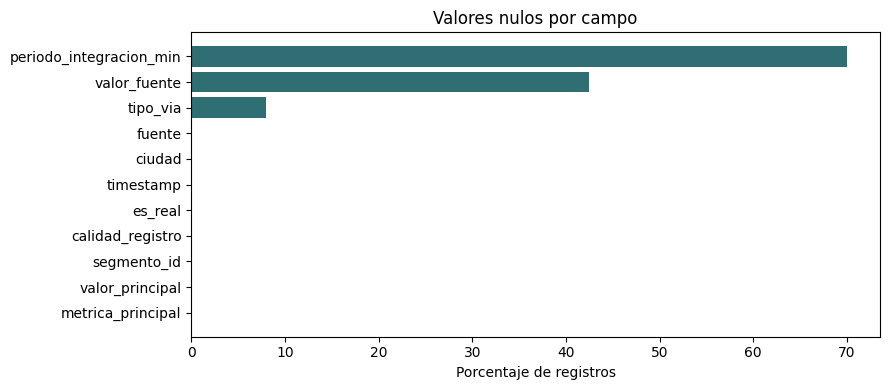

,campo,nulos,total,porcentaje_nulo
10,periodo_integracion_min,29258747,41770880,70.045800
9,valor_fuente,17738876,41770880,42.467087
5,tipo_via,3323698,41770880,7.956974
2,fuente,0,41770880,0.000000
1,ciudad,0,41770880,0.000000
0,timestamp,0,41770880,0.000000
3,es_real,0,41770880,0.000000
6,calidad_registro,0,41770880,0.000000
4,segmento_id,0,41770880,0.000000
8,valor_principal,0,41770880,0.000000


In [4]:
nulos_ordenados = nulos.sort_values("porcentaje_nulo", ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(nulos_ordenados["campo"], nulos_ordenados["porcentaje_nulo"], color="#2f6f73")
ax.set_title("Valores nulos por campo")
ax.set_xlabel("Porcentaje de registros")
ax.invert_yaxis()
plt.tight_layout()
plt.show()
nulos_ordenados

In [5]:
cobertura = pd.read_csv(TEMPORAL / "cobertura_diaria.csv")
horaria = pd.read_csv(TEMPORAL / "resumen_por_hora.csv")
cobertura_resumen = cobertura.groupby(["ciudad", "fuente", "metrica_principal"], as_index=False).agg(
    fecha_minima=("fecha", "min"),
    fecha_maxima=("fecha", "max"),
    dias_observados=("fecha", "nunique"),
)
horas_resumen = horaria.groupby(["ciudad", "fuente", "metrica_principal"], as_index=False).agg(
    horas_observadas=("hora", "nunique")
)
cobertura_resumen.merge(horas_resumen, on=["ciudad", "fuente", "metrica_principal"])

,ciudad,fuente,metrica_principal,fecha_minima,fecha_maxima,dias_observados,horas_observadas
0,Istanbul,istanbul_traffic_index,indice_congestion,2015-08-06,2024-10-18,3332,1
1,Los Angeles County,metr_la,velocidad_sensor,2012-03-01,2012-06-27,119,24
2,Madrid,madrid_traffic_points,intensidad,2022-12-01,2022-12-31,31,24
3,San Francisco Bay Area,pems_bay,velocidad_sensor,2017-01-01,2017-06-30,181,24
4,Sao Paulo,sao_paulo_cet,congestion_longitud_m,2001-01-02,2018-09-30,6094,24


In [6]:
matriz = pd.read_csv(COMPARISON / "matriz_comparabilidad.csv")
matriz

,ciudad,fuente,metrica_principal,familia_metrica,unidad_conceptual,comparacion_directa,condicion_comparacion
0,Sao Paulo,sao_paulo_cet,congestion_longitud_m,congestion_longitud,longitud congestionada,False,no comparar en escala original
1,Istanbul,istanbul_traffic_index,indice_congestion,indice_congestion,indice relativo,False,no comparar en escala original
2,Madrid,madrid_traffic_points,intensidad,intensidad,intensidad de trafico,False,no comparar en escala original
3,Los Angeles County,metr_la,velocidad_sensor,velocidad,velocidad de sensor,True,verificar unidad y alinear ventana temporal
4,San Francisco Bay Area,pems_bay,velocidad_sensor,velocidad,velocidad de sensor,True,verificar unidad y alinear ventana temporal


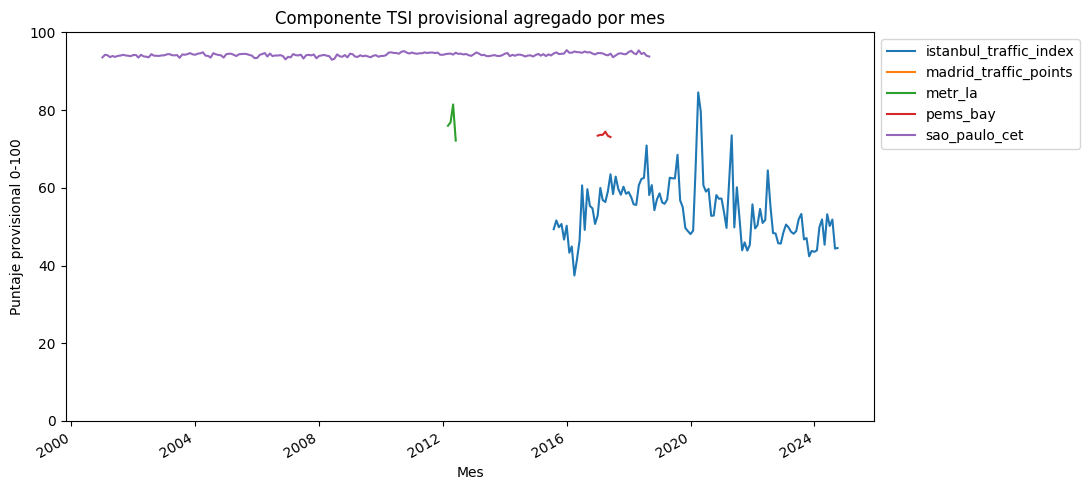

,ciudad,fuente,metrica_principal,meses,dias,media_tsi,minimo_tsi,maximo_tsi
0,Istanbul,istanbul_traffic_index,indice_congestion,111,3332,54.042888,37.440891,84.536247
1,Los Angeles County,metr_la,velocidad_sensor,4,119,76.593792,72.139647,81.440176
2,Madrid,madrid_traffic_points,intensidad,1,31,98.609834,98.609834,98.609834
3,San Francisco Bay Area,pems_bay,velocidad_sensor,6,181,73.586712,73.059386,74.430857
4,Sao Paulo,sao_paulo_cet,congestion_longitud_m,213,6094,94.231826,92.945834,95.424774


In [7]:
tsi_diario = pd.read_csv(TSI / "tsi_provisional_diario.csv")
tsi_diario["fecha"] = pd.to_datetime(tsi_diario["fecha"])
tsi_diario["mes"] = tsi_diario["fecha"].dt.to_period("M").dt.to_timestamp()
tsi_mensual = tsi_diario.groupby(["ciudad", "fuente", "metrica_principal", "mes"], as_index=False).agg(
    tsi_provisional_media=("tsi_provisional_media", "mean"),
    dias=("fecha", "nunique"),
)
fig, ax = plt.subplots(figsize=(11, 5))
for fuente, grupo in tsi_mensual.groupby("fuente"):
    grupo_ordenado = grupo.sort_values("mes")
    ax.plot(grupo_ordenado["mes"], grupo_ordenado["tsi_provisional_media"], label=fuente, linewidth=1.5)
ax.set_title("Componente TSI provisional agregado por mes")
ax.set_xlabel("Mes")
ax.set_ylabel("Puntaje provisional 0-100")
ax.set_ylim(0, 100)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
tsi_mensual.groupby(["ciudad", "fuente", "metrica_principal"], as_index=False).agg(
    meses=("mes", "nunique"),
    dias=("dias", "sum"),
    media_tsi=("tsi_provisional_media", "mean"),
    minimo_tsi=("tsi_provisional_media", "min"),
    maximo_tsi=("tsi_provisional_media", "max"),
)

## Hallazgos del EDA ejecutado

- El consolidado contiene 41.770.880 observaciones y cinco grupos ciudad-fuente-metrica.
- `periodo_integracion_min` y `valor_fuente` presentan faltantes dependientes de la fuente.
- Istanbul tiene una observacion diaria; las fuentes de sensores tienen cobertura intradia.
- METR-LA y PEMS-BAY son candidatas a comparacion directa despues de verificar unidades y alinear periodos.
- El TSI mostrado es provisional y esta normalizado dentro de cada fuente; no representa un ranking internacional.
